In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
df = pd.read_csv("../data/water_potability.csv")

print("Dataset shape:", df.shape)

Dataset shape: (3276, 10)


In [3]:
X = df.drop(columns=["Potability"])
y = df["Potability"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [5]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler()),

    ("classifier", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

In [8]:
model.fit(X_train, y_train)

print("SVM training completed!")

C:\Users\ankit\Desktop\ml project is here\WaterQualityPrediction\ml\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM training completed!


In [9]:
y_pred = model.predict(X_test)

In [10]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("\nSVM Evaluation")
print("----------------")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)


SVM Evaluation
----------------
Accuracy : 0.6707317073170732
Precision: 0.7040816326530612
Recall   : 0.26953125
F1 Score : 0.3898305084745763


In [11]:
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)


Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.93      0.77       400
           1       0.70      0.27      0.39       256

    accuracy                           0.67       656
   macro avg       0.68      0.60      0.58       656
weighted avg       0.68      0.67      0.62       656



In [13]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)


Confusion Matrix:
[[371  29]
 [187  69]]


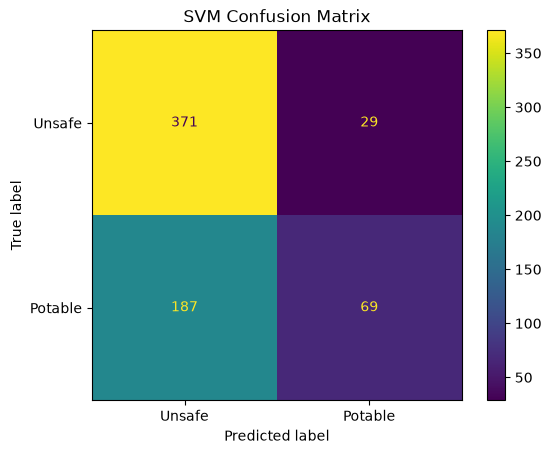

In [14]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Unsafe", "Potable"]
)

disp.plot()

plt.title("SVM Confusion Matrix")

plt.show()

In [15]:
probabilities = model.predict_proba(X_test)

print("\nFirst 5 prediction probabilities:")
print(probabilities[:5])


First 5 prediction probabilities:
[[0.77212363 0.22787637]
 [0.78855993 0.21144007]
 [0.8112272  0.1887728 ]
 [0.74118388 0.25881612]
 [0.73914282 0.26085718]]


In [16]:
for c in [0.1, 1, 10, 100]:

    svm_model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),

        ("scaler", StandardScaler()),

        ("classifier", SVC(
            kernel="rbf",
            C=c,
            probability=True,
            random_state=42
        ))
    ])

    svm_model.fit(X_train, y_train)

    prediction = svm_model.predict(X_test)

    score = accuracy_score(
        y_test,
        prediction
    )

    print(
        f"C: {c} | "
        f"Accuracy: {score:.4f}"
    )

C:\Users\ankit\Desktop\ml project is here\WaterQualityPrediction\ml\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C: 0.1 | Accuracy: 0.6159


C:\Users\ankit\Desktop\ml project is here\WaterQualityPrediction\ml\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C: 1 | Accuracy: 0.6707


C:\Users\ankit\Desktop\ml project is here\WaterQualityPrediction\ml\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C: 10 | Accuracy: 0.6387


C:\Users\ankit\Desktop\ml project is here\WaterQualityPrediction\ml\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C: 100 | Accuracy: 0.5823


In [17]:
for kernel in ["linear", "rbf"]:

    svm_model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),

        ("scaler", StandardScaler()),

        ("classifier", SVC(
            kernel=kernel,
            probability=True,
            random_state=42
        ))
    ])

    svm_model.fit(X_train, y_train)

    prediction = svm_model.predict(X_test)

    score = accuracy_score(
        y_test,
        prediction
    )

    print(
        f"Kernel: {kernel} | "
        f"Accuracy: {score:.4f}"
    )

C:\Users\ankit\Desktop\ml project is here\WaterQualityPrediction\ml\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Kernel: linear | Accuracy: 0.6098


C:\Users\ankit\Desktop\ml project is here\WaterQualityPrediction\ml\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Kernel: rbf | Accuracy: 0.6707
